In [0]:
import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as f
from pyspark.sql import types as t
from pyspark.sql import DataFrame
from functools import reduce
from delta.tables import DeltaTable
import requests, zipfile, io
import re
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from pathlib import Path
from datetime import datetime
import pprint
import os
import json
import time

In [0]:
aluno_geral = spark.read.csv("/Volumes/case_asn/data/portal_asn/alunos_geral.csv", header=True)
display(aluno_geral)

inicio,cadastro,matricula_id,curso_id,titulo_curso,aluno_id,expira,suporte,status,cadastro_data
NA,2025-11-18T13:34:08Z,22604,20,IDA,1078,2027-01-01T23:59:59Z,2026-11-18T23:59:59Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22605,23,Aulas ao Vivo Universo dos Dados,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22606,29,IDA - Curso Python,1078,2027-01-01T23:59:59Z,2026-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22608,38,Séries Temporais Prof° Daniel Ferreira,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22609,39,Redes Neurais e Inteligência Artificial,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22610,40,"SQL, ABT e Ferramentas de DEV",1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22611,41,Monitoração de Modelos,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22612,42,Fraudes e Crimes Financeiros,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22613,43,Modelagem e Risco de Crédito,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22614,44,Support Vector Machine - SVM,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18


In [0]:
progresso = spark.read.csv("/Volumes/case_asn/data/portal_asn/progresso.csv", header=True)
display(progresso)

curso_id,matricula_id,progresso,curso_titulo,aluno_id,aulas_acessadas,carga_horaria,ultimo_acesso
20,22604,0,IDA,1078,0,00:00:00,NA
23,22605,0,Aulas ao Vivo Universo dos Dados,1078,0,00:00:00,NA
29,22606,0,IDA - Curso Python,1078,0,00:00:00,NA
38,22608,0,Séries Temporais Prof° Daniel Ferreira,1078,0,00:00:00,NA
39,22609,0,Redes Neurais e Inteligência Artificial,1078,0,00:00:00,NA
40,22610,0,"SQL, ABT e Ferramentas de DEV",1078,0,00:00:00,NA
41,22611,0,Monitoração de Modelos,1078,0,00:00:00,NA
42,22612,0,Fraudes e Crimes Financeiros,1078,0,00:00:00,NA
43,22613,0,Modelagem e Risco de Crédito,1078,0,00:00:00,NA
44,22614,0,Support Vector Machine - SVM,1078,0,00:00:00,NA


In [0]:
progresso.select("curso_titulo").distinct().display()

curso_titulo
Séries Temporais Prof° Daniel Ferreira
Monitoração de Modelos
Marketing Science e Modelos de Atribuição
Business Inteligence com Power BI
Monetização de algorítimos
Técnicas Avançadas
Redes Neurais e Inteligência Artificial
Introdução a Computação
Machine Learning Avançado
Machine Learning com Python e DataBricks


In [0]:
progresso_total = spark.read.csv("/Volumes/case_asn/data/portal_asn/progresso_total.csv", header=True)
display(progresso_total)

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,ultima_visualizacao,tempo_aula,data_conclusao,aula_concluido
217,20,IDA,217,1118,O que é probabilidade?,1215,2026-01-09T19:57:25Z,00:20:41,2026-01-09T19:41:10Z,1
217,20,IDA,217,1118,O que é probabilidade?,1201,2025-12-28T21:03:50Z,00:29:14,2025-12-09T18:13:35Z,1
217,20,IDA,217,1118,O que é probabilidade?,1195,2026-01-14T11:04:14Z,00:16:53,2025-12-21T01:58:57Z,1
217,20,IDA,217,1118,O que é probabilidade?,1224,2026-01-11T16:15:57Z,00:16:39,2026-01-06T19:22:41Z,1
217,20,IDA,217,1118,O que é probabilidade?,1213,2026-01-07T08:46:31Z,00:14:48,2026-01-06T11:36:58Z,1
217,20,IDA,217,1118,O que é probabilidade?,1090,2025-11-24T15:10:35Z,00:16:01,2025-11-24T14:55:22Z,1
217,20,IDA,217,1118,O que é probabilidade?,1080,2025-11-23T23:35:51Z,00:15:35,2025-11-23T23:22:10Z,1
217,20,IDA,217,1119,Distribuição Estatística,1215,2026-01-09T20:38:15Z,00:43:40,2026-01-09T20:15:01Z,1
217,20,IDA,217,1119,Distribuição Estatística,1201,2025-12-28T21:50:19Z,01:54:06,2025-12-09T18:31:37Z,1
217,20,IDA,217,1119,Distribuição Estatística,1195,2026-01-14T11:08:50Z,00:44:57,2026-01-11T13:13:50Z,1


Databricks visualization. Run in Databricks to view.

In [0]:
from pyspark.sql.functions import col, expr, when

progresso_tratado = (
    progresso_total
    # Converter string -> timestamp (tolerando erro como "NA")
    .withColumn(
        "ultima_visualizacao_ts",
        expr("try_to_timestamp(ultima_visualizacao, \"yyyy-MM-dd'T'HH:mm:ssX\")")
    )
    .withColumn(
        "data_conclusao_ts",
        expr("try_to_timestamp(data_conclusao, \"yyyy-MM-dd'T'HH:mm:ssX\")")
    )

    # Comparação
    .withColumn(
        "comparacao",
        when(col("ultima_visualizacao_ts") > col("data_conclusao_ts"), "MAIOR")
        .when(col("ultima_visualizacao_ts") < col("data_conclusao_ts"), "MENOR")
        .when(
            col("ultima_visualizacao_ts").isNull() | col("data_conclusao_ts").isNull(),
            "INVALIDO"
        )
        .otherwise("IGUAL")
    )
)

progresso_tratado.display()

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,ultima_visualizacao,tempo_aula,data_conclusao,aula_concluido,ultima_visualizacao_ts,data_conclusao_ts,comparacao
217,20,IDA,217,1118,O que é probabilidade?,1215,2026-01-09T19:57:25Z,00:20:41,2026-01-09T19:41:10Z,1,2026-01-09T19:57:25.000Z,2026-01-09T19:41:10.000Z,MAIOR
217,20,IDA,217,1118,O que é probabilidade?,1201,2025-12-28T21:03:50Z,00:29:14,2025-12-09T18:13:35Z,1,2025-12-28T21:03:50.000Z,2025-12-09T18:13:35.000Z,MAIOR
217,20,IDA,217,1118,O que é probabilidade?,1195,2026-01-14T11:04:14Z,00:16:53,2025-12-21T01:58:57Z,1,2026-01-14T11:04:14.000Z,2025-12-21T01:58:57.000Z,MAIOR
217,20,IDA,217,1118,O que é probabilidade?,1224,2026-01-11T16:15:57Z,00:16:39,2026-01-06T19:22:41Z,1,2026-01-11T16:15:57.000Z,2026-01-06T19:22:41.000Z,MAIOR
217,20,IDA,217,1118,O que é probabilidade?,1213,2026-01-07T08:46:31Z,00:14:48,2026-01-06T11:36:58Z,1,2026-01-07T08:46:31.000Z,2026-01-06T11:36:58.000Z,MAIOR
217,20,IDA,217,1118,O que é probabilidade?,1090,2025-11-24T15:10:35Z,00:16:01,2025-11-24T14:55:22Z,1,2025-11-24T15:10:35.000Z,2025-11-24T14:55:22.000Z,MAIOR
217,20,IDA,217,1118,O que é probabilidade?,1080,2025-11-23T23:35:51Z,00:15:35,2025-11-23T23:22:10Z,1,2025-11-23T23:35:51.000Z,2025-11-23T23:22:10.000Z,MAIOR
217,20,IDA,217,1119,Distribuição Estatística,1215,2026-01-09T20:38:15Z,00:43:40,2026-01-09T20:15:01Z,1,2026-01-09T20:38:15.000Z,2026-01-09T20:15:01.000Z,MAIOR
217,20,IDA,217,1119,Distribuição Estatística,1201,2025-12-28T21:50:19Z,01:54:06,2025-12-09T18:31:37Z,1,2025-12-28T21:50:19.000Z,2025-12-09T18:31:37.000Z,MAIOR
217,20,IDA,217,1119,Distribuição Estatística,1195,2026-01-14T11:08:50Z,00:44:57,2026-01-11T13:13:50Z,1,2026-01-14T11:08:50.000Z,2026-01-11T13:13:50.000Z,MAIOR


In [0]:
progresso_tratado.groupby("comparacao").count().display()

comparacao,count
IGUAL,168
MAIOR,1304
INVALIDO,15


In [0]:
from pyspark.sql.functions import expr, col, sum as _sum, concat, lpad, lit

verifica = (
    progresso_total
    # Converter curso_id e aluno_id para inteiro (com tolerância a erro)
    .withColumn("curso_id", col("curso_id").cast("int"))
    .withColumn("aluno_id", col("aluno_id").cast("int"))

    # Converter tempo HH:mm:ss -> segundos (robusto)
    .withColumn(
        "tempo_segundos",
        expr("""
            coalesce(try_cast(get(split(tempo_aula, ':'), 0) as int), 0) * 3600 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 1) as int), 0) * 60 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 2) as int), 0)
        """)
    )

    # Agrupar e somar
    .groupBy("curso_id", "aluno_id")
    .agg(_sum("tempo_segundos").alias("total_segundos"))

    # Converter segundos -> HH:mm:ss
    .withColumn(
        "tempo_total",
        concat(
            lpad((col("total_segundos") / 3600).cast("int"), 2, "0"), lit(":"),
            lpad(((col("total_segundos") % 3600) / 60).cast("int"), 2, "0"), lit(":"),
            lpad((col("total_segundos") % 60).cast("int"), 2, "0")
        )
    )
)

#verifica.orderBy("curso_id", "aluno_id").display()


df2 = progresso.withColumn("curso_id", col("curso_id").cast("int")) \
                  .withColumn("aluno_id", col("aluno_id").cast("int"))

df2 = df2.select("curso_id", "aluno_id", "carga_horaria")               

df_union = verifica.join(
    df2,
    on=["curso_id", "aluno_id"]
    , how="left"
)

display(df_union)

curso_id,aluno_id,total_segundos,tempo_total,carga_horaria
20,1080,121185,33:39:45,81:39:45
20,1086,84,00:01:24,00:01:24
23,1089,365,00:06:05,00:06:05
67,1088,0,00:00:00,00:00:00
92,1201,0,00:00:00,00:00:00
92,1080,460,00:07:40,00:07:40
78,1226,0,00:00:00,00:00:00
81,1211,0,00:00:00,00:00:00
81,428,0,00:00:00,00:00:00
96,1197,7275,02:01:15,02:01:15


In [0]:
usuario_geral = spark.read.csv("/Volumes/case_asn/data/portal_asn/usuarios_geral.csv", header=True)
display(usuario_geral)

aluno_id,data_cadastro,ultimo_acesso,uf,tipo,status,username
1102,2025-11-18T22:14:39Z,2026-01-18T17:44:57Z,NA,1,1,Aluno
1196,2025-11-28T10:09:14Z,2026-01-20T17:15:26Z,NA,1,1,Aluno
1085,2025-11-18T21:16:13Z,2026-01-23T14:21:54Z,NA,1,1,Aluno
1200,2025-11-28T14:01:21Z,2026-01-20T13:47:45Z,NA,1,1,Aluno
1103,2025-11-18T22:18:43Z,2026-01-21T20:51:52Z,NA,1,1,Aluno
1088,2025-11-18T21:29:47Z,2026-01-23T08:10:54Z,NA,1,1,Aluno
1099,2025-11-18T21:56:19Z,2026-01-23T08:59:55Z,NA,1,1,Aluno
1087,2025-11-18T21:29:29Z,2026-01-23T11:08:57Z,NA,1,1,Aluno
1215,2025-11-28T21:25:55Z,2026-01-23T13:20:33Z,NA,1,1,Aluno
1201,2025-11-28T14:06:58Z,2026-01-24T00:05:49Z,NA,1,1,Aluno


In [0]:
tempo_aula = spark.read.csv("/Volumes/case_asn/data/portal_asn/tempo_aula.csv", header=True)
display(tempo_aula)

curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,Tempo
20,IDA,217,1118,O que é probabilidade?,0:14:37
20,IDA,217,1119,Distribuição Estatística,0:43:49
20,IDA,217,1120,Tipos de Distribuições,0:09:38
20,IDA,217,1121,Distribuição Discreta - Uniforme,0:05:16
20,IDA,217,1122,Distribuição Discreta - Bernoulli,0:06:53
20,IDA,217,1123,Distribuição Discreta - Binomial,0:20:32
20,IDA,217,1124,Distribuição Discreta - Poisson,0:11:37
20,IDA,217,1125,Distribuições Contínuas - Normal - Parte 2,0:28:46
20,IDA,217,1126,Distribuições Contínuas - Normal - Parte 3,0:08:25
20,IDA,217,1127,Distribuições Contínuas - Exponencial,0:05:47


## 1. Dimensão: Frequência

In [0]:
progresso_total.display()

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,ultima_visualizacao,tempo_aula,data_conclusao,aula_concluido
217,20,IDA,217,1118,O que é probabilidade?,1215,2026-01-09T19:57:25Z,00:20:41,2026-01-09T19:41:10Z,1
217,20,IDA,217,1118,O que é probabilidade?,1201,2025-12-28T21:03:50Z,00:29:14,2025-12-09T18:13:35Z,1
217,20,IDA,217,1118,O que é probabilidade?,1195,2026-01-14T11:04:14Z,00:16:53,2025-12-21T01:58:57Z,1
217,20,IDA,217,1118,O que é probabilidade?,1224,2026-01-11T16:15:57Z,00:16:39,2026-01-06T19:22:41Z,1
217,20,IDA,217,1118,O que é probabilidade?,1213,2026-01-07T08:46:31Z,00:14:48,2026-01-06T11:36:58Z,1
217,20,IDA,217,1118,O que é probabilidade?,1090,2025-11-24T15:10:35Z,00:16:01,2025-11-24T14:55:22Z,1
217,20,IDA,217,1118,O que é probabilidade?,1080,2025-11-23T23:35:51Z,00:15:35,2025-11-23T23:22:10Z,1
217,20,IDA,217,1119,Distribuição Estatística,1215,2026-01-09T20:38:15Z,00:43:40,2026-01-09T20:15:01Z,1
217,20,IDA,217,1119,Distribuição Estatística,1201,2025-12-28T21:50:19Z,01:54:06,2025-12-09T18:31:37Z,1
217,20,IDA,217,1119,Distribuição Estatística,1195,2026-01-14T11:08:50Z,00:44:57,2026-01-11T13:13:50Z,1


In [0]:
base_frequencia = (progresso_total
    .withColumn("aluno_id", col("aluno_id").cast("int"))
    .withColumn(
        "ultima_visualizacao",
        expr("try_to_timestamp(ultima_visualizacao, \"yyyy-MM-dd'T'HH:mm:ssX\")")
    )
    .withColumn(
        "data_visualizacao",
        f.to_date(col("ultima_visualizacao"))
    )
    .withColumn(
        "tempo_segundos",
        expr("""
            coalesce(try_cast(get(split(tempo_aula, ':'), 0) as int), 0) * 3600 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 1) as int), 0) * 60 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 2) as int), 0)
        """).cast("int")
    )
    # Filtro correto (>= 3 minutos)
    .where(col("tempo_segundos") >= 180)
    .groupBy("aluno_id").agg(f.countDistinct("data_visualizacao").alias("Frequencia_Dias"))
    )      


base_frequencia.display()

aluno_id,Frequencia_Dias
1092,7
1195,16
1160,6
1088,4
1100,3
1222,4
1089,12
1094,6
1220,6
1084,1


## 2. Dimensão: Progresso

In [0]:
display(progresso)

curso_id,matricula_id,progresso,curso_titulo,aluno_id,aulas_acessadas,carga_horaria,ultimo_acesso
20,22604,0,IDA,1078,0,00:00:00,NA
23,22605,0,Aulas ao Vivo Universo dos Dados,1078,0,00:00:00,NA
29,22606,0,IDA - Curso Python,1078,0,00:00:00,NA
38,22608,0,Séries Temporais Prof° Daniel Ferreira,1078,0,00:00:00,NA
39,22609,0,Redes Neurais e Inteligência Artificial,1078,0,00:00:00,NA
40,22610,0,"SQL, ABT e Ferramentas de DEV",1078,0,00:00:00,NA
41,22611,0,Monitoração de Modelos,1078,0,00:00:00,NA
42,22612,0,Fraudes e Crimes Financeiros,1078,0,00:00:00,NA
43,22613,0,Modelagem e Risco de Crédito,1078,0,00:00:00,NA
44,22614,0,Support Vector Machine - SVM,1078,0,00:00:00,NA


In [0]:
display(aluno_geral)

inicio,cadastro,matricula_id,curso_id,titulo_curso,aluno_id,expira,suporte,status,cadastro_data
NA,2025-11-18T13:34:08Z,22604,20,IDA,1078,2027-01-01T23:59:59Z,2026-11-18T23:59:59Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22605,23,Aulas ao Vivo Universo dos Dados,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22606,29,IDA - Curso Python,1078,2027-01-01T23:59:59Z,2026-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22608,38,Séries Temporais Prof° Daniel Ferreira,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22609,39,Redes Neurais e Inteligência Artificial,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22610,40,"SQL, ABT e Ferramentas de DEV",1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22611,41,Monitoração de Modelos,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22612,42,Fraudes e Crimes Financeiros,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22613,43,Modelagem e Risco de Crédito,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18
NA,2025-11-18T13:34:09Z,22614,44,Support Vector Machine - SVM,1078,2027-01-01T23:59:59Z,2025-11-18T13:34:09Z,Matrícula ativa,2025-11-18


In [0]:
p = progresso.alias("p")
a = aluno_geral.alias("a")

# BASE: cursos ativos (join correto + filtro)
base = (
    p.join(a, on=["matricula_id"], how="inner")
     .where(
        (f.col("a.status") == "Matrícula ativa") &
        (f.col("p.curso_titulo") != "Comece por aqui")
     )
)

# DENOMINADOR: cursos únicos por aluno + dias de casa (NOVO)
denominador = (
    base
    .select("p.aluno_id", "p.curso_id", "a.cadastro_data")
    .dropDuplicates(["aluno_id", "curso_id"]) # Garante a contagem certa de cursos
    .groupBy("p.aluno_id")
    .agg(
        f.countDistinct("p.curso_id").alias("qtd_cursos_ativos"),
        f.min("a.cadastro_data").alias("cadastro_data") # Pega a data de entrada
    )
    .withColumn(
        "dias_de_casa",
        f.greatest(f.datediff(f.current_date(), f.col("cadastro_data")), f.lit(1))
    )
)

# NUMERADOR: consolidar por curso e filtrar carga > 10 min (VOLTOU AO ORIGINAL)
numerador = (
    base
    .withColumn(
        "tempo_segundos",
        f.coalesce(f.split(f.col("p.carga_horaria"), ":").getItem(0).cast("int"), f.lit(0)) * 3600 +
        f.coalesce(f.split(f.col("p.carga_horaria"), ":").getItem(1).cast("int"), f.lit(0)) * 60 +
        f.coalesce(f.split(f.col("p.carga_horaria"), ":").getItem(2).cast("int"), f.lit(0))
    )
    # garante 1 linha por curso
    .groupBy("p.aluno_id", "p.curso_id")
    .agg(
        f.max("tempo_segundos").alias("tempo_segundos"),
        f.max("p.progresso").alias("progresso")
    )
    .where(f.col("tempo_segundos") >= 600)
    .groupBy("aluno_id")
    .agg(f.sum("progresso").alias("soma_progresso"))
)

# RESULTADO FINAL: Onde a mágica da velocidade acontece
dm_progresso = (
    denominador.join(numerador, on="aluno_id", how="left")
    .fillna({"soma_progresso": 0})
    .withColumn(
        "progresso_plataforma_absoluto", # Esse vai pro Dashboard (ex: 45%)
        (f.col("soma_progresso") / f.col("qtd_cursos_ativos"))
    )
    .withColumn(
        "velocidade_progresso", # Esse vai pros Percentis (ex: 1.5% ao dia)
        (f.col("progresso_plataforma_absoluto") / f.col("dias_de_casa"))
    )
    .drop("cadastro_data") # Limpa a sujeira do dataframe
)

dm_progresso.display()

aluno_id,qtd_cursos_ativos,dias_de_casa,soma_progresso,progresso_plataforma_absoluto,velocidade_progresso
1033,49,158,42.42,0.8657142857142858,0.005479204339963834
1078,47,168,0.0,0.0,0.0
1079,47,168,12.74,0.27106382978723403,0.0016134751773049644
1080,47,168,64.17,1.3653191489361702,0.008126899696048632
1083,47,168,0.0,0.0,0.0
1085,47,168,13.64,0.2902127659574468,0.0017274569402228978
1086,47,168,13.64,0.2902127659574468,0.0017274569402228978
1087,47,168,45.43,0.9665957446808511,0.0057535460992907805
1088,47,168,4.55,0.09680851063829787,5.76241134751773E-4
1089,47,168,34.14,0.7263829787234043,0.0043237082066869305


## 3. Dimensão: Profundidade

In [0]:
display(progresso_total)

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,ultima_visualizacao,tempo_aula,data_conclusao,aula_concluido
217,20,IDA,217,1118,O que é probabilidade?,1215,2026-01-09T19:57:25Z,00:20:41,2026-01-09T19:41:10Z,1
217,20,IDA,217,1118,O que é probabilidade?,1201,2025-12-28T21:03:50Z,00:29:14,2025-12-09T18:13:35Z,1
217,20,IDA,217,1118,O que é probabilidade?,1195,2026-01-14T11:04:14Z,00:16:53,2025-12-21T01:58:57Z,1
217,20,IDA,217,1118,O que é probabilidade?,1224,2026-01-11T16:15:57Z,00:16:39,2026-01-06T19:22:41Z,1
217,20,IDA,217,1118,O que é probabilidade?,1213,2026-01-07T08:46:31Z,00:14:48,2026-01-06T11:36:58Z,1
217,20,IDA,217,1118,O que é probabilidade?,1090,2025-11-24T15:10:35Z,00:16:01,2025-11-24T14:55:22Z,1
217,20,IDA,217,1118,O que é probabilidade?,1080,2025-11-23T23:35:51Z,00:15:35,2025-11-23T23:22:10Z,1
217,20,IDA,217,1119,Distribuição Estatística,1215,2026-01-09T20:38:15Z,00:43:40,2026-01-09T20:15:01Z,1
217,20,IDA,217,1119,Distribuição Estatística,1201,2025-12-28T21:50:19Z,01:54:06,2025-12-09T18:31:37Z,1
217,20,IDA,217,1119,Distribuição Estatística,1195,2026-01-14T11:08:50Z,00:44:57,2026-01-11T13:13:50Z,1


In [0]:
base_profundidade = (
    progresso_total
    .withColumn(
        "tempo_segundos",
        expr("""
            coalesce(try_cast(get(split(tempo_aula, ':'), 0) as int), 0) * 3600 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 1) as int), 0) * 60 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 2) as int), 0)
        """)
    )
    .groupBy("aluno_id")
    .agg(
        f.sum("tempo_segundos").alias("profundidade_total_segundos")
        )
     # converter pra minutos (sua métrica final)
    .withColumn(
        "profundidade_total_minutos",
        f.col("profundidade_total_segundos") / 60
    )
)

base_profundidade.display()

aluno_id,profundidade_total_segundos,profundidade_total_minutos
1090,19373,322.8833333333333
1080,220704,3678.4
1085,99967,1666.1166666666666
1102,11446,190.76666666666668
1160,66616,1110.2666666666667
1207,99499,1658.3166666666666
1232,3891,64.85
1030,13,0.21666666666666667
1210,19939,332.31666666666666
831,0,0.0


## 4. Dimensão: Revisão

In [0]:
display(progresso_total)

log_id,curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,aluno_id,ultima_visualizacao,tempo_aula,data_conclusao,aula_concluido
217,20,IDA,217,1118,O que é probabilidade?,1215,2026-01-09T19:57:25Z,00:20:41,2026-01-09T19:41:10Z,1
217,20,IDA,217,1118,O que é probabilidade?,1201,2025-12-28T21:03:50Z,00:29:14,2025-12-09T18:13:35Z,1
217,20,IDA,217,1118,O que é probabilidade?,1195,2026-01-14T11:04:14Z,00:16:53,2025-12-21T01:58:57Z,1
217,20,IDA,217,1118,O que é probabilidade?,1224,2026-01-11T16:15:57Z,00:16:39,2026-01-06T19:22:41Z,1
217,20,IDA,217,1118,O que é probabilidade?,1213,2026-01-07T08:46:31Z,00:14:48,2026-01-06T11:36:58Z,1
217,20,IDA,217,1118,O que é probabilidade?,1090,2025-11-24T15:10:35Z,00:16:01,2025-11-24T14:55:22Z,1
217,20,IDA,217,1118,O que é probabilidade?,1080,2025-11-23T23:35:51Z,00:15:35,2025-11-23T23:22:10Z,1
217,20,IDA,217,1119,Distribuição Estatística,1215,2026-01-09T20:38:15Z,00:43:40,2026-01-09T20:15:01Z,1
217,20,IDA,217,1119,Distribuição Estatística,1201,2025-12-28T21:50:19Z,01:54:06,2025-12-09T18:31:37Z,1
217,20,IDA,217,1119,Distribuição Estatística,1195,2026-01-14T11:08:50Z,00:44:57,2026-01-11T13:13:50Z,1


In [0]:
display(tempo_aula)

curso_id,curso_titulo,modulo_id,aula_id,aula_titulo,Tempo
20,IDA,217,1118,O que é probabilidade?,0:14:37
20,IDA,217,1119,Distribuição Estatística,0:43:49
20,IDA,217,1120,Tipos de Distribuições,0:09:38
20,IDA,217,1121,Distribuição Discreta - Uniforme,0:05:16
20,IDA,217,1122,Distribuição Discreta - Bernoulli,0:06:53
20,IDA,217,1123,Distribuição Discreta - Binomial,0:20:32
20,IDA,217,1124,Distribuição Discreta - Poisson,0:11:37
20,IDA,217,1125,Distribuições Contínuas - Normal - Parte 2,0:28:46
20,IDA,217,1126,Distribuições Contínuas - Normal - Parte 3,0:08:25
20,IDA,217,1127,Distribuições Contínuas - Exponencial,0:05:47


In [0]:
progresso_total.columns

['log_id',
 'curso_id',
 'curso_titulo',
 'modulo_id',
 'aula_id',
 'aula_titulo',
 'aluno_id',
 'ultima_visualizacao',
 'tempo_aula',
 'data_conclusao',
 'aula_concluido']

In [0]:
pt = progresso_total.alias("pt")
t = tempo_aula.alias("t")

base_revisao = (
    pt.join(t, on=["curso_id", "modulo_id", "aula_id"], how="left")
    .select(
        'pt.log_id',
        'pt.curso_id',
        'pt.curso_titulo',
        'pt.modulo_id',
        'pt.aula_id',
        'pt.aula_titulo',
        'pt.aluno_id',
        'pt.ultima_visualizacao',
        f.col('pt.tempo_aula').alias("tempo_assistido"),
        'pt.data_conclusao',
        'pt.aula_concluido',
        f.col('t.tempo').alias("tempo_aula")
    )
    .withColumn(
        "tempo_assistido_segundos",
        expr("""
            coalesce(try_cast(get(split(tempo_assistido, ':'), 0) as int), 0) * 3600 +
            coalesce(try_cast(get(split(tempo_assistido, ':'), 1) as int), 0) * 60 +
            coalesce(try_cast(get(split(tempo_assistido, ':'), 2) as int), 0)
        """)
    )
    .withColumn(
        "tempo_aula_segundos",
        expr("""
            coalesce(try_cast(get(split(tempo_aula, ':'), 0) as int), 0) * 3600 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 1) as int), 0) * 60 +
            coalesce(try_cast(get(split(tempo_aula, ':'), 2) as int), 0)
        """)
    )
    .where(f.col("tempo_assistido_segundos")> f.col("tempo_aula_segundos"))
    .groupBy("aluno_id")
    .agg(f.countDistinct(f.col("aula_id")).alias("qtd_aula_revistas"))
    
)


display(base_revisao)

aluno_id,qtd_aula_revistas
1080,89
1160,5
1207,13
1085,16
1090,8
1102,5
1232,1
1096,3
1210,10
1089,12


## 5. Dimensão: Recência

In [0]:
display(progresso)

curso_id,matricula_id,progresso,curso_titulo,aluno_id,aulas_acessadas,carga_horaria,ultimo_acesso
20,22604,0,IDA,1078,0,00:00:00,NA
23,22605,0,Aulas ao Vivo Universo dos Dados,1078,0,00:00:00,NA
29,22606,0,IDA - Curso Python,1078,0,00:00:00,NA
38,22608,0,Séries Temporais Prof° Daniel Ferreira,1078,0,00:00:00,NA
39,22609,0,Redes Neurais e Inteligência Artificial,1078,0,00:00:00,NA
40,22610,0,"SQL, ABT e Ferramentas de DEV",1078,0,00:00:00,NA
41,22611,0,Monitoração de Modelos,1078,0,00:00:00,NA
42,22612,0,Fraudes e Crimes Financeiros,1078,0,00:00:00,NA
43,22613,0,Modelagem e Risco de Crédito,1078,0,00:00:00,NA
44,22614,0,Support Vector Machine - SVM,1078,0,00:00:00,NA


In [0]:
p = progresso.alias("p")
a = aluno_geral.alias("a")


base_recencia = (
    p.join(a, on=["matricula_id"], how="inner")

    .withColumn(
        "ultimo_acesso_ts",
        expr("try_to_timestamp(ultimo_acesso, \"yyyy-MM-dd'T'HH:mm:ssX\")")
    )

    .withColumn(
        "data_comparacao",
        f.when(
            f.col("ultimo_acesso_ts").isNull(),
            f.col("a.cadastro_data")
        ).otherwise(f.col("ultimo_acesso_ts"))
    )
    
    .groupBy("p.aluno_id")
    .agg(
        f.datediff(
            f.current_date(),
            f.max(f.to_date("data_comparacao"))
        ).alias("Dias_Recencia")
        )
)



base_recencia.display()

aluno_id,Dias_Recencia
1080,105
1085,105
1090,116
1030,168
1102,137
1160,104
1207,108
1232,156
1096,168
1210,149


## 6. ABT

In [0]:
base_frequencia
dm_progresso
base_profundidade
base_recencia
base_revisao

DataFrame[aluno_id: string, qtd_aula_revistas: bigint]

In [0]:
al = aluno_geral.alias("al")
fr = base_frequencia.alias("fr")
pr = dm_progresso.alias("pr")
pf = base_profundidade.alias("pf")
rc = base_recencia.alias("rc")
rv = base_revisao.alias("rv")

base_abt = (
    al.select("aluno_id").distinct()
    .join(fr, on=["aluno_id"], how="left")
    .join(pr, on=["aluno_id"], how="left")
    .join(pf, on=["aluno_id"], how="left")
    .join(rc, on=["aluno_id"], how="left")
    .join(rv, on=["aluno_id"], how="left")
    .select(
        f.col('aluno_id').alias("aluno"),
        f.col('Frequencia_Dias'),
        f.col('velocidade_progresso'),
        f.col('profundidade_total_segundos'),
        f.col('Dias_Recencia'),
        f.col('qtd_aula_revistas')
    )
    .fillna(0)
)

estatistica = base_abt.select(
    
    # FREQUENCIA
    f.percentile_approx("Frequencia_Dias", 0.25).alias("freq_p25"),
    f.percentile_approx("Frequencia_Dias", 0.5).alias("freq_mediana"),
    f.percentile_approx("Frequencia_Dias", 0.75).alias("freq_p75"),
    f.avg("Frequencia_Dias").alias("freq_media"),
    f.stddev("Frequencia_Dias").alias("freq_std"),

    # PROGRESSO
    f.percentile_approx("velocidade_progresso", 0.25).alias("prog_p25"),
    f.percentile_approx("velocidade_progresso", 0.5).alias("prog_mediana"),
    f.percentile_approx("velocidade_progresso", 0.75).alias("prog_p75"),
    f.avg("velocidade_progresso").alias("prog_media"),
    f.stddev("velocidade_progresso").alias("prog_std"),

    # PROFUNDIDADE
    f.percentile_approx("profundidade_total_segundos", 0.25).alias("prof_p25"),
    f.percentile_approx("profundidade_total_segundos", 0.5).alias("prof_mediana"),
    f.percentile_approx("profundidade_total_segundos", 0.75).alias("prof_p75"),
    f.avg("profundidade_total_segundos").alias("prof_media"),
    f.stddev("profundidade_total_segundos").alias("prof_std"),

    # RECENCIA
    f.percentile_approx("Dias_Recencia", 0.25).alias("rec_p25"),
    f.percentile_approx("Dias_Recencia", 0.5).alias("rec_mediana"),
    f.percentile_approx("Dias_Recencia", 0.75).alias("rec_p75"),
    f.avg("Dias_Recencia").alias("rec_media"),
    f.stddev("Dias_Recencia").alias("rec_std"),

    # REVISAO
    f.percentile_approx("qtd_aula_revistas", 0.25).alias("rev_p25"),
    f.percentile_approx("qtd_aula_revistas", 0.5).alias("rev_mediana"),
    f.percentile_approx("qtd_aula_revistas", 0.75).alias("rev_p75"),
    f.avg("qtd_aula_revistas").alias("rev_media"),
    f.stddev("qtd_aula_revistas").alias("rev_std")

).collect()[0]

base_abt = (base_abt
    .withColumn(
        "frequencia",
        f.when((f.col('Frequencia_Dias') <= estatistica["freq_p25"]), "Baixo")
         .when((f.col('Frequencia_Dias') >= estatistica["freq_p75"]), "Alto")
         .otherwise("Medio")
    )
    .withColumn(
        "progresso",
        f.when((f.col('velocidade_progresso') <= estatistica["prog_p25"]), "Baixo")
         .when((f.col('velocidade_progresso') >= estatistica["prog_p75"]), "Alto")
         .otherwise("Medio")
    )
    .withColumn(
        "profundidade",
        f.when((f.col('profundidade_total_segundos') <= estatistica["prof_p25"]), "Baixo")
         .when((f.col('profundidade_total_segundos') >= estatistica["prof_p75"]), "Alto")
         .otherwise("Medio")
    )
    .withColumn(
        # Iverso 
        "recencia",
        f.when((f.col('Dias_Recencia') <= estatistica["rec_p25"]), "Alto")
         .when((f.col('Dias_Recencia') >= estatistica["rec_p75"]), "Baixo")
         .otherwise("Medio")
    )
    .withColumn(
        "revisao",
        f.when((f.col('qtd_aula_revistas') <= estatistica["rev_p25"]), "Baixo")
         .when((f.col('qtd_aula_revistas') >= estatistica["rev_p75"]), "Alto")
         .otherwise("Medio")
    )

    #Padronização
    .withColumn(
        "frequencia_pr",
        ((f.col('Frequencia_Dias') - estatistica["freq_media"]) / estatistica["freq_std"])
    )
    .withColumn(
        "progresso_pr",
        ((f.col('velocidade_progresso') - estatistica["prog_media"]) / estatistica["prog_std"])
    )
    .withColumn(
        "profundidade_pr",
        ((f.col('profundidade_total_segundos') - estatistica["prof_media"]) / estatistica["prof_std"])
    )
    .withColumn(
        # INVERTIDO: Média menos o valor do aluno. Assim, quem tem muitos dias fica com score negativo!
        "recencia_pr",
        ((estatistica["rec_media"] - f.col('Dias_Recencia')) / estatistica["rec_std"])
    )
    .withColumn(
        "revisao_pr",
        ((f.col('qtd_aula_revistas') - estatistica["rev_media"]) / estatistica["rev_std"])
    )
    # Pesos
    # Recência: 40% (Peso altíssimo)
    # Progresso (Velocidade): 20%
    # Frequência: 20%
    # Profundidade: 10%
    # Revisão: 10%
    .withColumn(
        "frequencia_peso",
        (f.col('frequencia_pr') * 0.20)
    )
    .withColumn(
        "progresso_peso",
        (f.col('progresso_pr') * 0.20)
    )
    .withColumn(
        "profundidade_peso",
        (f.col('profundidade_pr') * 0.10)
    )
    .withColumn(
        # Iverso 
        "recencia_peso",
        (f.col('recencia_pr') * 0.40)
    )
    .withColumn(
        "revisao_peso",
        (f.col('revisao_pr') * 0.10)
    )
    # Score de Engajamento
    .withColumn(
        "score_classificao",
        (f.col("frequencia_peso")   + 
         f.col("progresso_peso")    + 
         f.col("profundidade_peso") + 
         f.col("recencia_peso")     +
         f.col("revisao_peso")
         )
    )
    .withColumn(
        "classificao_ordinal",
        (
        # 1º A REGRA DE OURO (Kill Switch)
        f.when(f.col("recencia") == "Baixo", "Alto Risco")

        # 2º A MATEMÁTICA (Se ele passou da regra de ouro, olhamos o score)
         .when(f.col("score_classificao") <= -1.5, "Alto Risco")
         .when((f.col("score_classificao") > -1.5) & (f.col("score_classificao") <= -0.5), "Em Risco")
         .when((f.col("score_classificao") > -0.5) & (f.col("score_classificao") <= 0.5), "Parcial")
         .when((f.col("score_classificao") > 0.5) & (f.col("score_classificao") <= 1.5), "Acima da Média")
         .when(f.col("score_classificao") > 1.5, "Engajado")
         .otherwise("Não Classificado")
        )
    )

)



base_abt_save = (base_abt
    .select(
        'aluno',
        'frequencia',
        'progresso',
        'profundidade',
        'recencia',
        'revisao',
        'score_classificao',
        'classificao_ordinal'
    )
)


base_abt_save.display()

aluno,frequencia,progresso,profundidade,recencia,revisao,score_classificao,classificao_ordinal
1080,Alto,Alto,Alto,Alto,Alto,2.290575277078105,Engajado
1085,Alto,Medio,Alto,Alto,Alto,0.6922330628982094,Acima da Média
1090,Medio,Medio,Medio,Medio,Medio,0.08325742105861447,Parcial
1030,Baixo,Baixo,Baixo,Baixo,Baixo,-1.161459168660981,Alto Risco
1102,Medio,Medio,Medio,Medio,Medio,-0.38734540409224427,Parcial
1160,Medio,Medio,Alto,Alto,Medio,0.3886680039570005,Parcial
1207,Alto,Medio,Alto,Medio,Alto,0.6375386611289736,Acima da Média
1232,Medio,Medio,Medio,Baixo,Medio,-0.84826997955776,Alto Risco
1096,Baixo,Baixo,Medio,Baixo,Medio,-1.0926966149016126,Alto Risco
1210,Medio,Alto,Medio,Medio,Medio,0.49915101700152287,Parcial


In [0]:



# base_abt_save.write \
#     .format("delta") \
#     .mode("overwrite") \
#     .option("overwriteSchema", "true") \
#     .saveAsTable("case_asn.data.abt_engajamento")

In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
import pyspark.sql.functions as f

# 1. Empacotar as colunas padronizadas em um Vetor (Exigência do Spark ML)
colunas_features = [
    "frequencia_pr", 
    "progresso_pr", 
    "profundidade_pr", 
    "recencia_pr", 
    "revisao_pr"
]

assembler = VectorAssembler(
    inputCols=colunas_features, 
    outputCol="features",
    handleInvalid="skip" # Evita que valores nulos quebrem o modelo
)

base_ml = assembler.transform(base_abt)

# 2. Configurar o Algoritmo K-Means
# Vamos chutar 'k=4' (4 grupos de alunos) para começar. 
# O 'seed' garante que o resultado seja o mesmo toda vez que rodar.
kmeans = KMeans(k=4, seed=42, featuresCol="features", predictionCol="cluster")

# 3. Treinar o Modelo
modelo_kmeans = kmeans.fit(base_ml)

# 4. Aplicar o Modelo (Prever o cluster de cada aluno)
base_clusterizada = modelo_kmeans.transform(base_ml)

# 5. Avaliar a qualidade matemática da clusterização (Silhouette Score)
# Varia de -1 a 1. Quanto mais perto de 1, mais bem definidos estão os grupos.
avaliador = ClusteringEvaluator(predictionCol="cluster", featuresCol="features")
silhouette = avaliador.evaluate(base_clusterizada)
print(f"Qualidade do Cluster (Silhouette Score): {silhouette}")

# Visualizar o resultado (Trazemos o aluno e o número do cluster dele)
base_clusterizada.select("aluno", "cluster", *colunas_features).show()

Qualidade do Cluster (Silhouette Score): 0.5501113818501481
+-----+-------+--------------------+--------------------+--------------------+-------------------+--------------------+
|aluno|cluster|       frequencia_pr|        progresso_pr|     profundidade_pr|        recencia_pr|          revisao_pr|
+-----+-------+--------------------+--------------------+--------------------+-------------------+--------------------+
| 1080|      1|  2.5749350637204054|   2.539174789145505|  3.1272667370757934| 0.9284390009822755|   5.836510324044331|
| 1085|      3|  0.8981263246339682|-0.02550015497603614|  1.0088440635845142| 0.9284390009822755|  0.4544782221526128|
| 1090|      3|0.059721955090749755| -0.3107460126044364|-0.40523908364753713|0.46879873107551384| -0.1353335150410002|
| 1030|      0| -0.9463632883611125| -0.7178050478677406| -0.7449250370735057| -1.704046181210996| -0.7251452522346132|
| 1102|      0|-0.10795891881789395|  -0.560956814350682| -0.5443243394743787|-0.4086963296555766|-0

In [0]:
# Perfilamento dos Clusters
perfil_clusters = (
    base_clusterizada
    .groupBy("cluster")
    .agg(
        f.count("aluno").alias("qtd_alunos"),
        f.avg("Frequencia_Dias").alias("media_dias_freq"),
        f.avg("velocidade_progresso").alias("media_velocidade"),
        f.avg("profundidade_total_segundos").alias("media_segundos"),
        f.avg("Dias_Recencia").alias("media_recencia")
    )
    .orderBy("cluster")
)

perfil_clusters.show()

+-------+----------+------------------+--------------------+------------------+------------------+
|cluster|qtd_alunos|   media_dias_freq|    media_velocidade|    media_segundos|    media_recencia|
+-------+----------+------------------+--------------------+------------------+------------------+
|      0|        39|1.4615384615384615|2.773344243468517E-4| 6453.410256410257|141.30769230769232|
|      1|         1|              21.0|0.008126899696048632|          220704.0|             105.0|
|      2|         6|18.666666666666668|0.004573266890920117|156771.66666666666|104.16666666666667|
|      3|        27| 8.222222222222221|0.003124692735519...| 62489.96296296296|112.81481481481481|
+-------+----------+------------------+--------------------+------------------+------------------+



In [0]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

# Configura o avaliador de Silhueta
avaliador = ClusteringEvaluator(predictionCol="prediction", featuresCol="features", metricName="silhouette", distanceMeasure="squaredEuclidean")

print("Iniciando a busca pelo K ideal...\n")

# Vamos testar K de 2 até 7
for k in range(2, 8):
    # Configura o modelo para o K atual
    kmeans = KMeans(featuresCol="features", k=k, seed=42)
    
    # Treina o modelo
    modelo = kmeans.fit(base_ml)
    
    # Aplica o modelo para gerar a coluna 'prediction'
    previsoes = modelo.transform(base_ml)
    
    # 1. Calcula o Silhouette Score
    silhueta = avaliador.evaluate(previsoes)
    
    # 2. Calcula o Erro Interno (WSSSE - Cost)
    wssse = modelo.summary.trainingCost
    
    print(f"K={k} | Silhouette Score: {silhueta:.4f} | Erro WSSSE: {wssse:.2f}")

print("\nFim do teste!")

Iniciando a busca pelo K ideal...



com.databricks.backend.common.rpc.CommandCancelledException
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$5(SequenceExecutionState.scala:139)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3(SequenceExecutionState.scala:139)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3$adapted(SequenceExecutionState.scala:136)
	at scala.collection.immutable.Range.foreach(Range.scala:192)
	at com.databricks.spark.chauffeur.SequenceExecutionState.cancel(SequenceExecutionState.scala:136)
	at com.databricks.spark.chauffeur.ExecContextState.cancelRunningSequence(ExecContextState.scala:725)
	at com.databricks.spark.chauffeur.ExecContextState.$anonfun$cancel$1(ExecContextState.scala:443)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.ExecContextState.cancel(ExecContextState.scala:443)
	at com.databricks.spark.chauffeur.ExecutionContextManagerV1.can

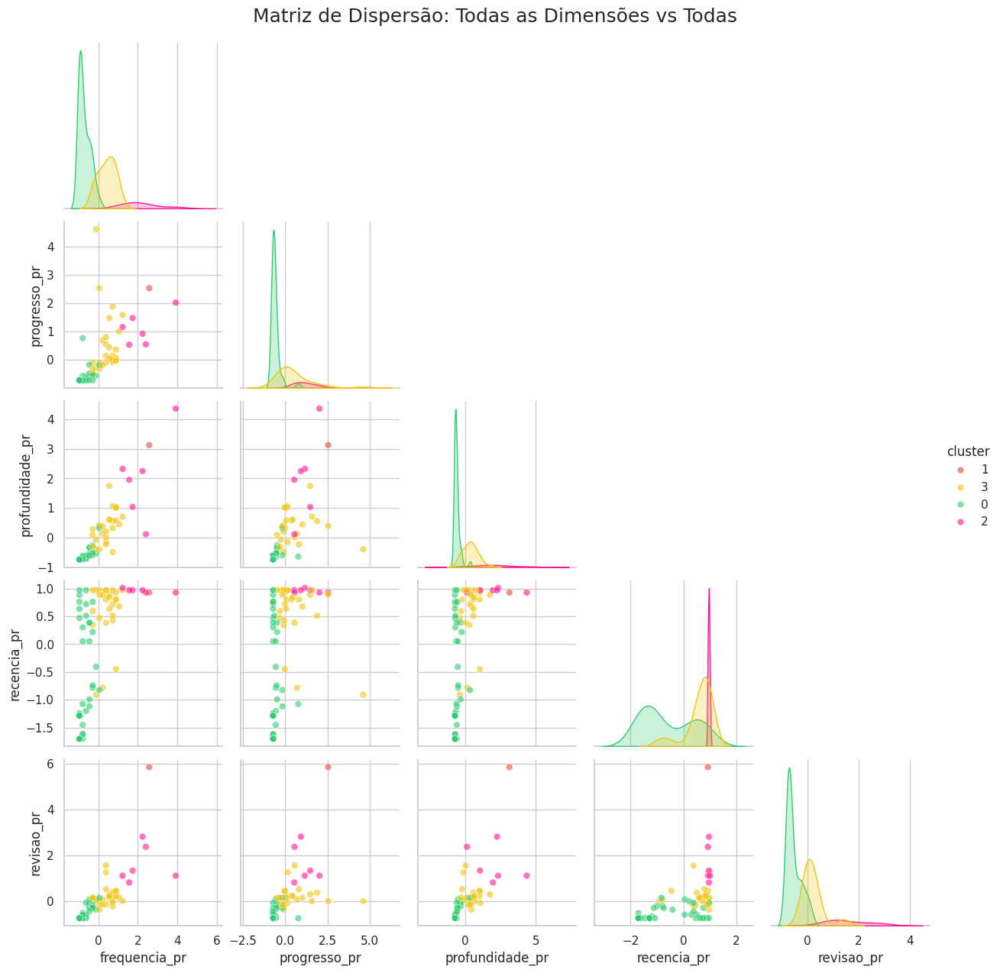

In [0]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Preparar os dados (Amostra + Pandas)
# Pegamos todas as nossas dimensões e o cluster
colunas_plot = [
    "frequencia_pr", 
    "progresso_pr", 
    "profundidade_pr", 
    "recencia_pr", 
    "revisao_pr", 
    "cluster"
]

# Pegamos uma amostra (ex: 10% ou 20%) para o gráfico gerar rápido e não travar a memória
df_pairplot = (
    base_clusterizada
    .select(*colunas_plot) 
    .toPandas()
)

# Garantimos que o cluster seja lido como "Categoria" e não como número de matemática
df_pairplot["cluster"] = df_pairplot["cluster"].astype(str)

# 2. Configurar o estilo visual
sns.set_theme(style="whitegrid")

# 3. Gerar a Matriz de Dispersão (Pairplot)
# O Seaborn faz todo o trabalho pesado mágico aqui
grafico_matriz = sns.pairplot(
    df_pairplot,
    hue="cluster", # Colore os pontos de acordo com o grupo
    palette=["#e74c3c", "#f1c40f", "#2ecc71", "#FF1493"], # Cores (Ajuste a ordem se o verde ficar no cluster errado)
    corner=True,   # Tira a parte espelhada para ficar mais limpo visualmente
    diag_kind="kde", # Na diagonal principal, desenha a "montanha" de distribuição
    plot_kws={'alpha': 0.6, 's': 40} # Deixa as bolinhas um pouco transparentes
)

# 4. Acabamentos
grafico_matriz.fig.suptitle("Matriz de Dispersão: Todas as Dimensões vs Todas", y=1.02, fontsize=18)
plt.show()